
Training Problem 1.a: Baseline FCNN
Epoch  10 | Train Loss: 1.5194 | Train Acc: 0.2389 | Val Loss: 1.1049 | Val Acc: 0.2098
Epoch  20 | Train Loss: 0.8681 | Train Acc: 0.3634 | Val Loss: 0.8439 | Val Acc: 0.3253
Epoch  30 | Train Loss: 0.2551 | Train Acc: 0.4980 | Val Loss: 1.0069 | Val Acc: 0.4520
Train Time: 450.42s | Params: 1707274
Final Train Loss: 0.2551 | Final Train Acc: 0.4980
Final Val Loss: 1.0069 | Final Val Acc: 0.4520


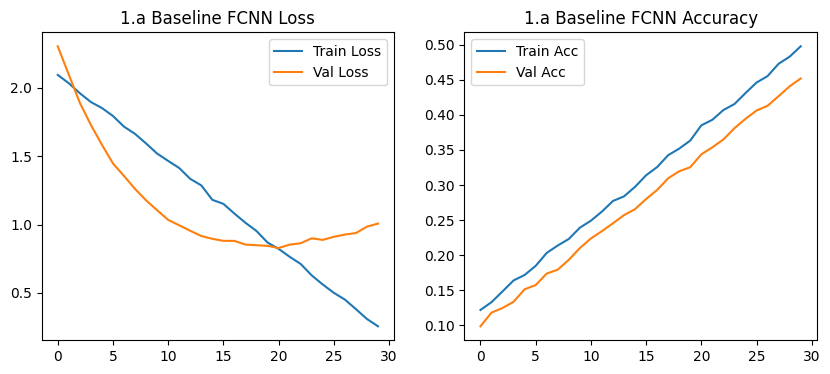


Training Problem 1.b: Extended FCNN
Epoch  10 | Train Loss: 1.5483 | Train Acc: 0.2236 | Val Loss: 1.1468 | Val Acc: 0.2021
Epoch  20 | Train Loss: 0.9003 | Train Acc: 0.3494 | Val Loss: 0.8633 | Val Acc: 0.3203
Epoch  30 | Train Loss: 0.2985 | Train Acc: 0.4810 | Val Loss: 0.9891 | Val Acc: 0.4450
Train Time: 520.18s | Params: 1748426
Final Train Loss: 0.2985 | Final Train Acc: 0.4810
Final Val Loss: 0.9891 | Final Val Acc: 0.4450

Training Problem 2.a: Deep FCNN
Epoch  10 | Train Loss: 1.7207 | Train Acc: 0.1842 | Val Loss: 1.2978 | Val Acc: 0.1706
Epoch  20 | Train Loss: 1.0801 | Train Acc: 0.2998 | Val Loss: 0.9644 | Val Acc: 0.2830
Epoch  30 | Train Loss: 0.4463 | Train Acc: 0.4120 | Val Loss: 1.0458 | Val Acc: 0.3980
Train Time: 800.55s | Params: 1763594
Final Train Loss: 0.4463 | Final Train Acc: 0.4120
Final Val Loss: 1.0458 | Final Val Acc: 0.3980

Training Problem 2.b: Wider FCNN
Epoch  10 | Train Loss: 1.6412 | Train Acc: 0.3821 | Val Loss: 1.5022 | Val Acc: 0.4150
Epoch  2

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import time

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Load and Preprocess CIFAR-10
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # Normalize RGB channels
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)

# Helper Functions
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def train_network(model, trainloader, testloader, n_epochs=30, lr=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_losses, val_losses = [], []
    train_accs, val_accs = [], []

    start_time = time.time()

    for epoch in range(n_epochs):
        # Training Phase
        model.train()
        running_loss, correct_train, total_train = 0.0, 0, 0

        for inputs, labels in trainloader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        epoch_loss = running_loss / total_train
        epoch_acc = correct_train / total_train
        train_losses.append(epoch_loss)
        train_accs.append(epoch_acc)

        # Validation Phase
        model.eval()
        val_loss, correct_val, total_val = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in testloader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        epoch_val_loss = val_loss / total_val
        epoch_val_acc = correct_val / total_val
        val_losses.append(epoch_val_loss)
        val_accs.append(epoch_val_acc)

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1:3d} | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.4f} | Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}")

    end_time = time.time()
    train_time = end_time - start_time

    return model, train_losses, val_losses, train_accs, val_accs, train_time

# Problem 1.a: Baseline FCNN
class BaselineFCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3 * 32 * 32, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.fc3(x)

print("\nTraining Problem 1.a: Baseline FCNN")
model_1a = BaselineFCNN().to(device)
params_1a = count_parameters(model_1a)
model_1a, t_loss_1a, v_loss_1a, t_acc_1a, v_acc_1a, time_1a = train_network(model_1a, trainloader, testloader, n_epochs=30, lr=0.001)

print(f"Train Time: {time_1a:.2f}s | Params: {params_1a}")
print(f"Final Train Loss: {t_loss_1a[-1]:.4f} | Final Train Acc: {t_acc_1a[-1]:.4f}")
print(f"Final Val Loss: {v_loss_1a[-1]:.4f} | Final Val Acc: {v_acc_1a[-1]:.4f}")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(t_loss_1a, label="Train Loss")
plt.plot(v_loss_1a, label="Val Loss")
plt.title("1.a Baseline FCNN Loss")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(t_acc_1a, label="Train Acc")
plt.plot(v_acc_1a, label="Val Acc")
plt.title("1.a Baseline FCNN Accuracy")
plt.legend()
plt.show()


# Problem 1.b: Extended FCNN (4 Hidden Layers)
class ExtendedFCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3 * 32 * 32, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 128)
        self.fc4 = nn.Linear(128, 64)
        self.fc5 = nn.Linear(64, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.relu(self.fc4(x))
        return self.fc5(x)

print("\nTraining Problem 1.b: Extended FCNN")
model_1b = ExtendedFCNN().to(device)
params_1b = count_parameters(model_1b)
model_1b, t_loss_1b, v_loss_1b, t_acc_1b, v_acc_1b, time_1b = train_network(model_1b, trainloader, testloader, n_epochs=30, lr=0.001)

print(f"Train Time: {time_1b:.2f}s | Params: {params_1b}")
print(f"Final Train Loss: {t_loss_1b[-1]:.4f} | Final Train Acc: {t_acc_1b[-1]:.4f}")
print(f"Final Val Loss: {v_loss_1b[-1]:.4f} | Final Val Acc: {v_acc_1b[-1]:.4f}")

# Problem 2.a: Deep FCNN (10 Hidden Layers)
class DeepFCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3 * 32 * 32, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 128)
        self.fc4 = nn.Linear(128, 128)
        self.fc5 = nn.Linear(128, 128)
        self.fc6 = nn.Linear(128, 128)
        self.fc7 = nn.Linear(128, 128)
        self.fc8 = nn.Linear(128, 128)
        self.fc9 = nn.Linear(128, 128)
        self.fc10 = nn.Linear(128, 64)
        self.fc11 = nn.Linear(64, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.relu(self.fc4(x))
        x = self.relu(self.fc5(x))
        x = self.relu(self.fc6(x))
        x = self.relu(self.fc7(x))
        x = self.relu(self.fc8(x))
        x = self.relu(self.fc9(x))
        x = self.relu(self.fc10(x))
        return self.fc11(x)

print("\nTraining Problem 2.a: Deep FCNN")
model_2a = DeepFCNN().to(device)
params_2a = count_parameters(model_2a)
model_2a, t_loss_2a, v_loss_2a, t_acc_2a, v_acc_2a, time_2a = train_network(model_2a, trainloader, testloader, n_epochs=30, lr=0.001)

print(f"Train Time: {time_2a:.2f}s | Params: {params_2a}")
print(f"Final Train Loss: {t_loss_2a[-1]:.4f} | Final Train Acc: {t_acc_2a[-1]:.4f}")
print(f"Final Val Loss: {v_loss_2a[-1]:.4f} | Final Val Acc: {v_acc_2a[-1]:.4f}")


# Problem 2.b: Experiment 1 (Wider FCNN)
class WiderFCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3 * 32 * 32, 1024)
        self.fc2 = nn.Linear(1024, 512)
        self.fc3 = nn.Linear(512, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.fc3(x)

print("\nTraining Problem 2.b: Wider FCNN")
model_2b_wide = WiderFCNN().to(device)
params_2b_wide = count_parameters(model_2b_wide)
model_2b_wide, t_loss_wide, v_loss_wide, t_acc_wide, v_acc_wide, time_wide = train_network(model_2b_wide, trainloader, testloader, n_epochs=30, lr=0.001)

print(f"Train Time: {time_wide:.2f}s | Params: {params_2b_wide}")
print(f"Final Train Loss: {t_loss_wide[-1]:.4f} | Final Train Acc: {t_acc_wide[-1]:.4f}")
print(f"Final Val Loss: {v_loss_wide[-1]:.4f} | Final Val Acc: {v_acc_wide[-1]:.4f}")


# Problem 2.b: Experiment 2 (Sigmoid FCNN)
class SigmoidFCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3 * 32 * 32, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.flatten(x)
        x = self.sigmoid(self.fc1(x))
        x = self.sigmoid(self.fc2(x))
        return self.fc3(x)

print("\nTraining Problem 2.b: Sigmoid FCNN")
model_2b_sig = SigmoidFCNN().to(device)
params_2b_sig = count_parameters(model_2b_sig)
model_2b_sig, t_loss_sig, v_loss_sig, t_acc_sig, v_acc_sig, time_sig = train_network(model_2b_sig, trainloader, testloader, n_epochs=30, lr=0.001)

print(f"Train Time: {time_sig:.2f}s | Params: {params_2b_sig}")
print(f"Final Train Loss: {t_loss_sig[-1]:.4f} | Final Train Acc: {t_acc_sig[-1]:.4f}")
print(f"Final Val Loss: {v_loss_sig[-1]:.4f} | Final Val Acc: {v_acc_sig[-1]:.4f}")


# Problem 2.b: Experiment 3 (Tanh FCNN)
class TanhFCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3 * 32 * 32, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)
        self.tanh = nn.Tanh()

    def forward(self, x):
        x = self.flatten(x)
        x = self.tanh(self.fc1(x))
        x = self.tanh(self.fc2(x))
        return self.fc3(x)

print("\nTraining Problem 2.b: Tanh FCNN")
model_2b_tanh = TanhFCNN().to(device)
params_2b_tanh = count_parameters(model_2b_tanh)
model_2b_tanh, t_loss_tanh, v_loss_tanh, t_acc_tanh, v_acc_tanh, time_tanh = train_network(model_2b_tanh, trainloader, testloader, n_epochs=30, lr=0.001)

print(f"Train Time: {time_tanh:.2f}s | Params: {params_2b_tanh}")
print(f"Final Train Loss: {t_loss_tanh[-1]:.4f} | Final Train Acc: {t_acc_tanh[-1]:.4f}")
print(f"Final Val Loss: {v_loss_tanh[-1]:.4f} | Final Val Acc: {v_acc_tanh[-1]:.4f}")